# Foundations of R Software – Week 11 (NPTEL)
**Lectures 43–49:** Data frames, importing/exporting data, descriptive statistics, scatter & bar plots.

> In Colab: *Runtime → Change runtime type → R*, then run cells top to bottom.

## 0. Setup

In [ ]:
install.packages(c("readxl", "writexl", "foreign", "haven", "XML"), quiet = TRUE)
library(MASS)      # painters data set
library(readxl)
library(foreign)
library(XML)

# Lecture 43 – Data Frames: Some More Operations

### The `painters` data frame (MASS)
Row names are the painters; columns are scores plus the `School` factor.

In [ ]:
head(painters)
str(painters)

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Da Udine,10,8,16,3,A
Da Vinci,15,16,4,14,A
Del Piombo,8,13,16,7,A
Del Sarto,12,16,9,8,A
Fr. Penni,0,15,8,0,A
Guilio Romano,15,16,4,14,A


'data.frame':	54 obs. of  5 variables:
 $ Composition: int  10 15 8 12 0 15 8 15 4 17 ...
 $ Drawing    : int  8 16 13 16 15 16 17 16 12 18 ...
 $ Colour     : int  16 4 16 9 8 4 4 7 10 12 ...
 $ Expression : int  3 14 7 8 0 14 8 6 4 18 ...
 $ School     : Factor w/ 8 levels "A","B","C","D",..: 1 1 1 1 1 1 1 1 1 1 ...


### `summary()` on categorical vs numeric variables

In [ ]:
summary(painters$School)       # frequency table for a factor
summary(painters$Composition)  # five-number summary + mean

A  B  C  D  E  F  G  H 
10  6  6 10  7  4  7  4

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    8.25   12.50   11.56   15.00   18.00 

### `attach()` / `detach()`
After `attach()`, columns can be used without the `painters$` prefix.

In [ ]:
attach(painters)
summary(School)        # character/factor variable
summary(Composition)   # numeric variable

A  B  C  D  E  F  G  H 
10  6  6 10  7  4  7  4

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    8.25   12.50   11.56   15.00   18.00 

In [ ]:
detach(painters)
# Now this fails, as shown in the lecture:
res <- try(summary(School), silent = TRUE)
cat(res)

Error in eval(expr, envir) : object 'School' not found


### Subsets with `subset()` and logical indexing

In [ ]:
subset(painters, School == 'F')

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Durer,8,10,10,8,F
Holbein,9,10,16,13,F
Pourbus,4,15,6,6,F
Van Leyden,8,6,6,4,F


In [ ]:
# Equivalent command
painters[painters[["School"]] == "F", ]

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Durer,8,10,10,8,F
Holbein,9,10,16,13,F
Pourbus,4,15,6,6,F
Van Leyden,8,6,6,4,F


In [ ]:
subset(painters, Composition <= 6)

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Fr. Penni,0,15,8,0,A
Perugino,4,12,10,4,A
Bassano,6,8,17,0,D
Bellini,4,6,14,0,D
Murillo,6,8,15,4,D
Palma Vecchio,5,6,16,0,D
Caravaggio,6,6,16,0,E
Pourbus,4,15,6,6,F


### Dropping uninteresting columns with `select`
Columns 3 (Colour) and 5 (School) are removed.

In [ ]:
subset(painters, School == "F", select = c(-3, -5))

,Composition,Drawing,Expression
,<int>,<int>,<int>
Durer,8,10,8
Holbein,9,10,13
Pourbus,4,15,6
Van Leyden,8,6,4


### `split()` – partition by a factor variable

In [ ]:
splitted <- split(painters, painters$School)
splitted          # list with elements $A ... $H

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Da Udine,10,8,16,3,A
Da Vinci,15,16,4,14,A
Del Piombo,8,13,16,7,A
Del Sarto,12,16,9,8,A
Fr. Penni,0,15,8,0,A
Guilio Romano,15,16,4,14,A
Michelangelo,8,17,4,8,A
Perino del Vaga,15,16,7,6,A
Perugino,4,12,10,4,A


In [ ]:
names(splitted)
is.data.frame(splitted$A)   # each element is itself a data frame
splitted$H

[1] "A" "B" "C" "D" "E" "F" "G" "H"

[1] TRUE

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
Bourdon,10,8,8,4,H
Le Brun,16,16,8,16,H
Le Suer,15,15,4,15,H
Poussin,15,17,6,15,H


# Lecture 46 – Importing & Reading Excel and Other Files

The lecture uses `spexcel.xlsx` (Sheet1: Variables 1–3, Sheet2: Variables 4–6). We **create** that file first so the notebook is self-contained.

> In Colab you could instead upload your own file with the Files panel; also `setwd("C:/RCourse/")` in the lecture is a Windows path – here we use the Colab working directory.

In [ ]:
library(writexl)
sheet1 <- data.frame(`Variable 1` = 1:5, `Variable 2` = seq(10, 50, 10),
                     `Variable 3` = seq(100, 500, 100), check.names = FALSE)
sheet2 <- data.frame(`Variable 4` = 6:10, `Variable 5` = seq(110, 150, 10),
                     `Variable 6` = seq(110, 510, 100), check.names = FALSE)
write_xlsx(list(Sheet1 = sheet1, Sheet2 = sheet2), "spexcel.xlsx")
getwd(); list.files(pattern = "spexcel")

[1] "/content"

[1] "spexcel.xlsx"

### `read_excel()` – by sheet number

In [ ]:
dataspexcel <- read_excel("spexcel.xlsx", sheet = 1)
dataspexcel

Variable 1,Variable 2,Variable 3
<dbl>,<dbl>,<dbl>
1,10,100
2,20,200
3,30,300
4,40,400
5,50,500


Extract a variable with `$` (backticks because of the space in the name).

In [ ]:
dataspexcel$`Variable 1`
dataspexcel$`Variable 2`
mean(dataspexcel$`Variable 1`)

[1] 1 2 3 4 5

[1] 10 20 30 40 50

[1] 3

### Second sheet

In [ ]:
dataspexcel2 <- read_excel("spexcel.xlsx", sheet = 2)
dataspexcel2
dataspexcel2$`Variable 4`
dataspexcel2$`Variable 5`
dataspexcel2$`Variable 6`
mean(dataspexcel2$`Variable 6`)

Variable 4,Variable 5,Variable 6
<dbl>,<dbl>,<dbl>
6,110,110
7,120,210
8,130,310
9,140,410
10,150,510


[1]  6  7  8  9 10

[1] 110 120 130 140 150

[1] 110 210 310 410 510

[1] 310

### Sheet by name

In [ ]:
read_excel("spexcel.xlsx", "Sheet2")

Variable 4,Variable 5,Variable 6
<dbl>,<dbl>,<dbl>
6,110,110
7,120,210
8,130,310
9,140,410
10,150,510


### Limit rows with `n_max`

In [ ]:
dataspexcel4 <- read_excel("spexcel.xlsx", n_max = 3)
dataspexcel4

Variable 1,Variable 2,Variable 3
<dbl>,<dbl>,<dbl>
1,10,100
2,20,200
3,30,300


### Read a cell range (A1 or R1C1 notation)
Note: the first row of the range becomes the column names – that's why the output headers are `1`, `10` in the lecture.

In [ ]:
dataspexcel5 <- read_excel("spexcel.xlsx", range = "A2:B3", sheet = 1)
dataspexcel5
dataspexcel6 <- read_excel("spexcel.xlsx", range = "A2:B3", sheet = 2)
dataspexcel6

1,10
<dbl>,<dbl>
2,20


6,110
<dbl>,<dbl>
7,120


In [ ]:
# Other forms from the slides
read_excel("spexcel.xlsx", range = "C1:E7")
# R1C1 notation (Row-Column): e.g. R1C2:R2C5 ; R2C3 = 2nd row, 3rd column
# read_excel("spexcel.xlsx", range = "R1C2:R2C5")

New names:
• `` -> `...2`
• `` -> `...3`


Variable 3,...2,...3
<dbl>,<lgl>,<lgl>
100,NA,NA
200,NA,NA
300,NA,NA
400,NA,NA
500,NA,NA
NA,NA,NA


### SPSS data (`foreign::read.spss`)
Template from the lecture:
```r
install.packages("foreign"); library(foreign)
data = read.spss("datafile.sav")
```
Demo below creates a small `.sav` with `haven`, then reads it back with `read.spss()`.

In [ ]:
library(haven)
write_sav(data.frame(x = 1:3, y = c(2.5, 3.5, 4.5)), "demo.sav")
spss_data <- read.spss("demo.sav", to.data.frame = TRUE)
spss_data

x,y
<dbl>,<dbl>
1,2.5
2,3.5
3,4.5


### HTML tables (`XML::readHTMLTable`)

In [ ]:
writeLines('<html><body><table>
<tr><th>Name</th><th>Marks</th></tr>
<tr><td>Asha</td><td>81</td></tr>
<tr><td>Ravi</td><td>67</td></tr>
</table></body></html>', "demo.html")
html_data <- readHTMLTable("demo.html")
html_data

Name,Marks
<chr>,<chr>
Asha,81
Ravi,67


### Other formats supported by `foreign`
| Function | Format |
|---|---|
| `read.octave("<path>")` | Octave / MATLAB |
| `read.systat("<path>")` | SYSTAT |
| `read.xport("<path>")` | SAS XPORT |
| `read.dta("<path>")` | Stata |

Round-trip demo with Stata format:

In [ ]:
write.dta(painters, "painters.dta")
head(read.dta("painters.dta"))

,Composition,Drawing,Colour,Expression,School
,<int>,<int>,<int>,<int>,<fct>
1,10,8,16,3,A
2,15,16,4,14,A
3,8,13,16,7,A
4,12,16,9,8,A
5,0,15,8,0,A
6,15,16,4,14,A


# Lecture 47 – Saving & Writing Data Files

### `write(x, file, ncolumns, append, sep)`
Default for numeric vectors is 5 columns, space separated.

In [ ]:
x <- c(1:100)
x
write(x, file = "shalabh")
cat(readLines("shalabh"), sep = "\n")   # view what was written

[1]   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
 [19]  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
 [37]  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
 [55]  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
 [73]  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
 [91]  91  92  93  94  95  96  97  98  99 100

1 2 3 4 5
6 7 8 9 10
11 12 13 14 15
16 17 18 19 20
21 22 23 24 25
26 27 28 29 30
31 32 33 34 35
36 37 38 39 40
41 42 43 44 45
46 47 48 49 50
51 52 53 54 55
56 57 58 59 60
61 62 63 64 65
66 67 68 69 70
71 72 73 74 75
76 77 78 79 80
81 82 83 84 85
86 87 88 89 90
91 92 93 94 95
96 97 98 99 100


In [ ]:
# ncolumns, sep and append
write(x[1:12], file = "shalabh2", ncolumns = 4, sep = "\t")
write(13:15, file = "shalabh2", ncolumns = 3, sep = "\t", append = TRUE)
cat(readLines("shalabh2"), sep = "\n")
# For a matrix m, write(t(m), ...) – transpose so columns match the matrix layout

1	2	3	4
5	6	7	8
9	10	11	12
13	14	15


### `write.csv()` and `write.table()`
Arguments discussed: `x`, `file`, `append`, `quote`, `sep`, `eol`, `na`, `row.names`, `col.names`.

In [ ]:
sub <- subset(painters, School == "F")
write.csv(sub, file = "painters_F.csv")
cat(readLines("painters_F.csv"), sep = "\n")

"","Composition","Drawing","Colour","Expression","School"
"Durer",8,10,10,8,"F"
"Holbein",9,10,16,13,"F"
"Pourbus",4,15,6,6,"F"
"Van Leyden",8,6,6,4,"F"


In [ ]:
write.table(sub, file = "painters_F.txt", sep = "\t", quote = FALSE,
            row.names = TRUE, col.names = TRUE, na = "NA")
cat(readLines("painters_F.txt"), sep = "\n")

Composition	Drawing	Colour	Expression	School
Durer	8	10	10	8	F
Holbein	9	10	16	13	F
Pourbus	4	15	6	6	F
Van Leyden	8	6	6	4	F


In [ ]:
# file = "" prints to the console; quote = FALSE removes double quotes
write.table(head(painters, 3), file = "", sep = ",", quote = FALSE)

Composition,Drawing,Colour,Expression,School
Da Udine,10,8,16,3,A
Da Vinci,15,16,4,14,A
Del Piombo,8,13,16,7,A


# Lecture 48 – Statistical Functions: Frequencies & Partition Values

**Descriptive statistics:** central tendency, variation, shape, relationships.

### Absolute and relative frequencies
10 persons coded 1 = Male, 2 = Female: n₁ = 7, n₂ = 3 → f₁ = 0.7 (70%), f₂ = 0.3 (30%).

In [ ]:
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)
gender
table(gender)                   # absolute frequencies
table(gender) / length(gender)  # relative frequencies

[1] 1 2 1 2 1 1 1 2 1 1

gender
1 2 
7 3 

gender
  1   2 
0.7 0.3 

### Pizza delivery example (3 branches: 1 = East, 2 = West, 3 = Central)

> ⚠️ The slide's vector was cut off in the PDF text (only 84 of 100 values were readable). The first 84 are exactly as on the slide; the last 16 are filled in so the totals match the lecture output (28 / 43 / 29).

In [ ]:
direction <- c(1,1,2,1,2,3,2,2,3,3,3,1,2,3,2,2,3,1,1,1,3,3,3,2,2,2,2,1,2,2,1,1,1,3,2,2,
               1,2,2,3,3,2,1,2,2,3,1,1,2,1,2,3,2,3,2,2,3,1,2,1,1,1,2,1,1,2,1,2,3,3,1,2,
               3,3,2,1,2,2,2,2,2,3,2,2,
               3,3,3,3,3,3,3,3,2,2,2,2,2,1,1,1)   # last 16 reconstructed
length(direction)
table(direction)                      # expected: 28 43 29
table(direction) / length(direction)  # expected: 0.28 0.43 0.29

[1] 100

direction
 1  2  3 
28 43 29 

direction
   1    2    3 
0.28 0.43 0.29 

### Partition values: `quantile()`
Quartiles (4 parts), deciles (10), percentiles (100).

In [ ]:
marks <- c(68, 82, 63, 86, 34, 96, 41, 89, 29, 51, 75, 77, 56, 59, 42)
quantile(marks)                                          # default quartiles
quantile(marks, probs = c(0, 0.25, 0.5, 0.75, 1))        # same, explicit
quantile(marks, probs = c(0, 0.20, 0.4, 0.6, 0.8, 1))    # quintiles

0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0

0%  25%  50%  75% 100% 
29.0 46.5 63.0 79.5 96.0

0%  20%  40%  60%  80% 100% 
29.0 41.8 57.8 70.8 82.8 96.0

In [ ]:
# Deciles and percentiles
quantile(marks, probs = seq(0, 1, 0.1))   # deciles
quantile(marks, probs = c(0.05, 0.95))    # selected percentiles

0%  10%  20%  30%  40%  50%  60%  70%  80%  90% 100% 
29.0 36.8 41.8 52.0 57.8 63.0 70.8 76.6 82.8 87.8 96.0

5%  95% 
32.5 91.1

# Lecture 49 – Graphics: Scatter Plot & Bar Plots

### Scatter plot with `plot(x)`
Heights (cm) of 50 persons.

> ⚠️ Two values (158, 159 at positions 31–32) were missing from the PDF text and were recovered from the scatter plot on the slide.

[1] 50

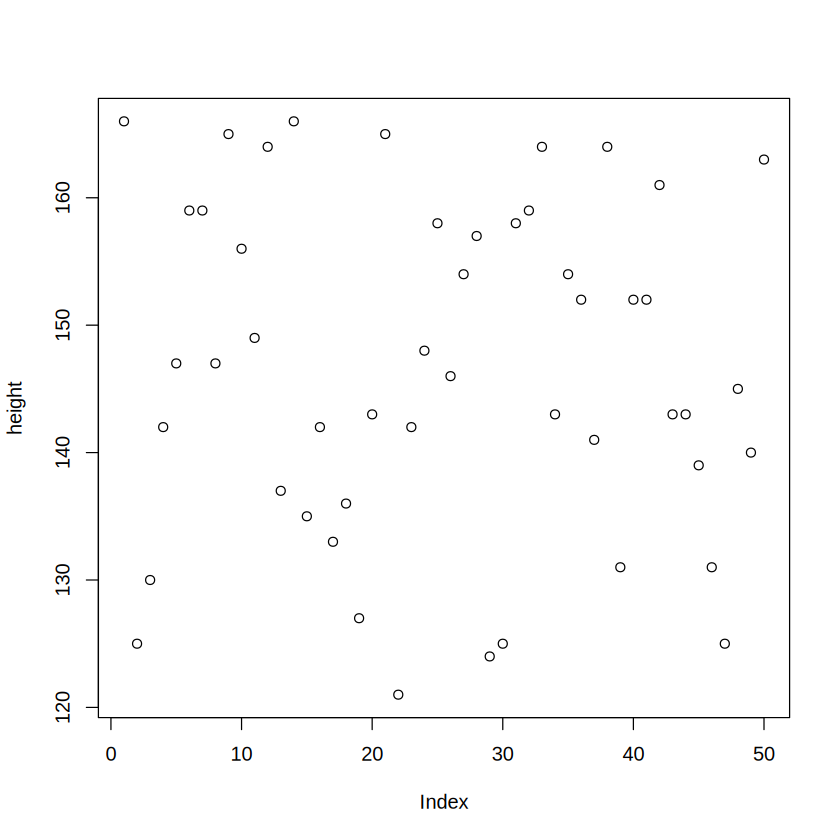

In [ ]:
height <- c(166,125,130,142,147,159,159,147,165,156,149,164,137,166,135,142,133,136,127,
            143,165,121,142,148,158,146,154,157,124,125,158,159,164,143,154,152,141,164,
            131,152,152,161,143,143,139,131,125,145,140,163)
length(height)
plot(height)

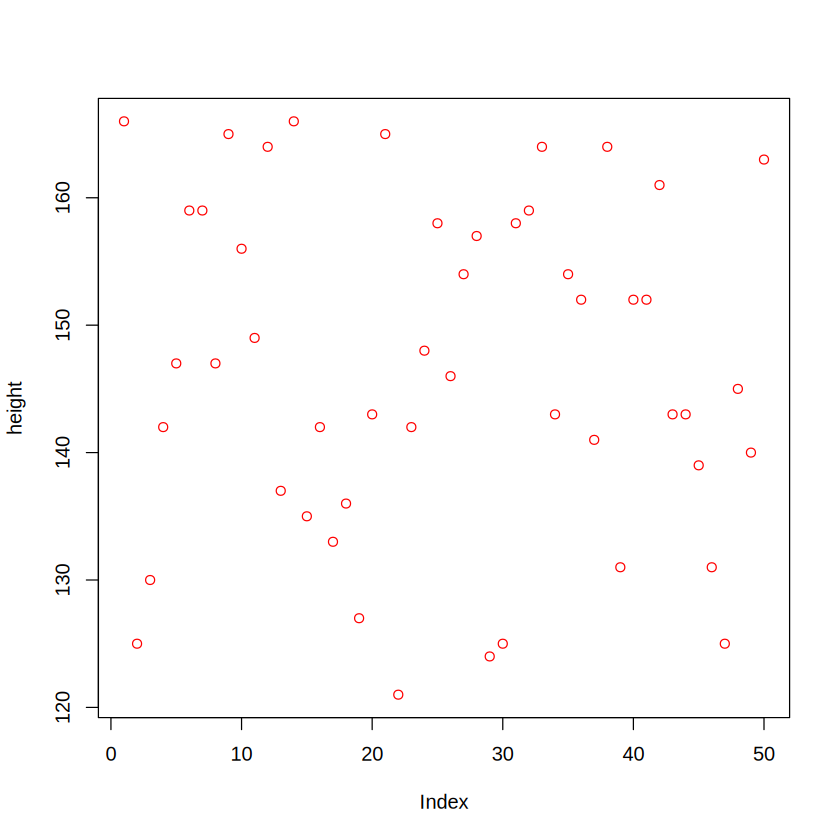

In [ ]:
plot(height, col = "red")

### Bar plots
For **categorical** variables only – one bar per category. Use `table()` first!

**Common mistake:** `barplot(gender)` draws one bar per *observation*.

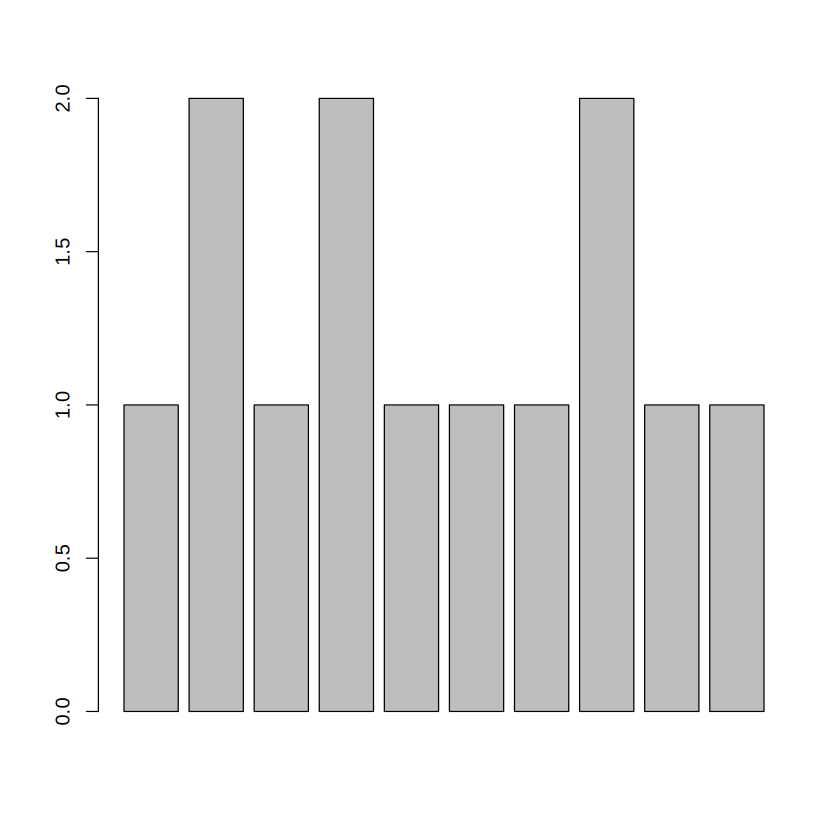

In [ ]:
barplot(gender)   # "Do you want this?"  -> usually NO

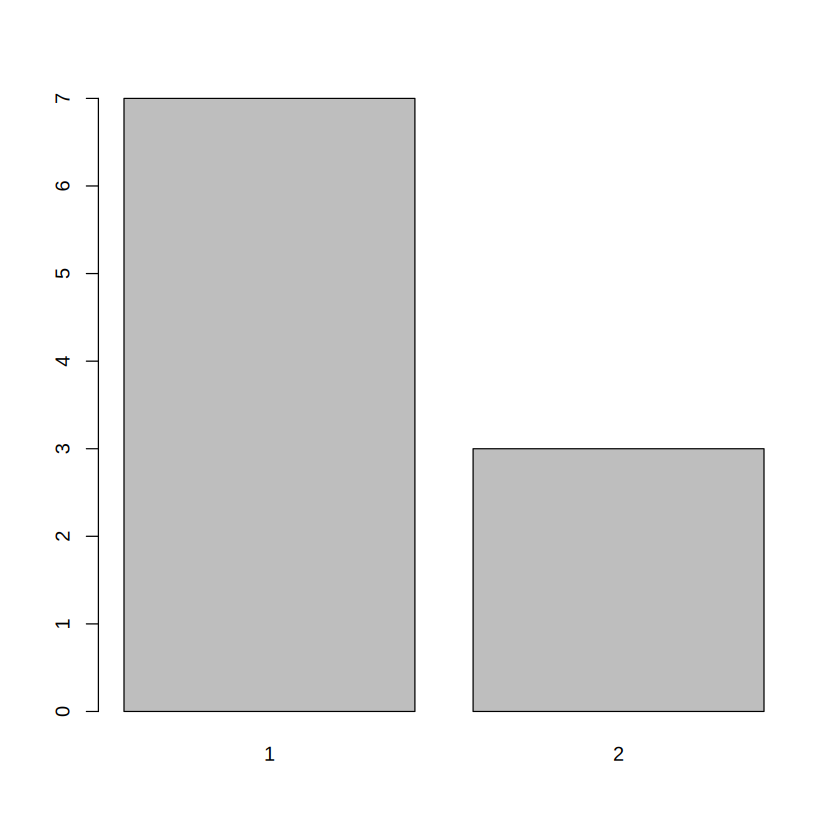

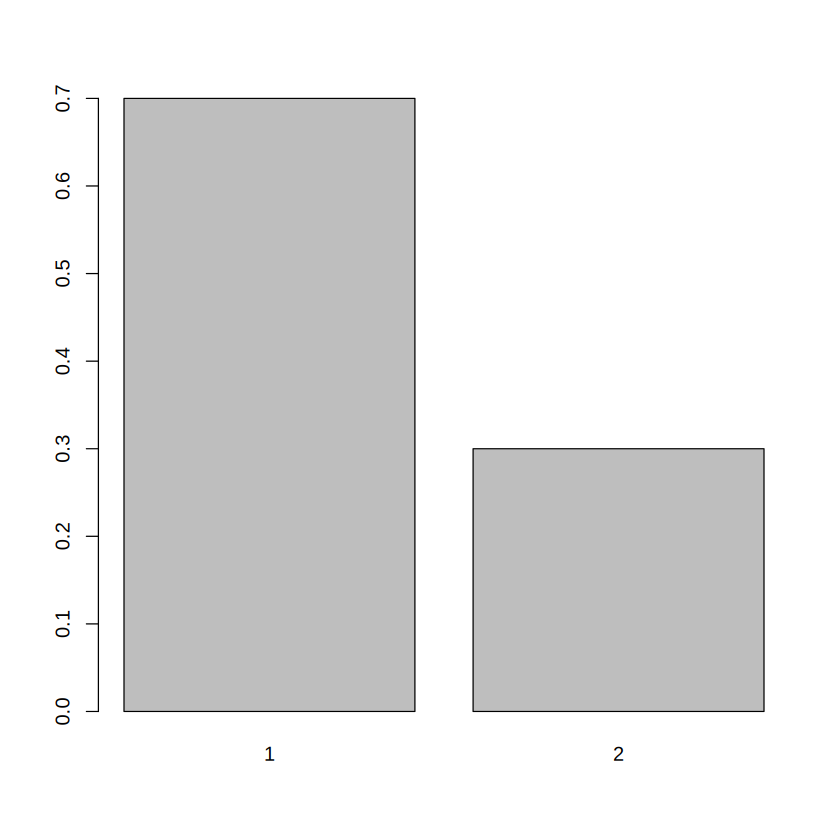

In [ ]:
barplot(table(gender))                      # absolute frequencies
barplot(table(gender) / length(gender))     # relative frequencies

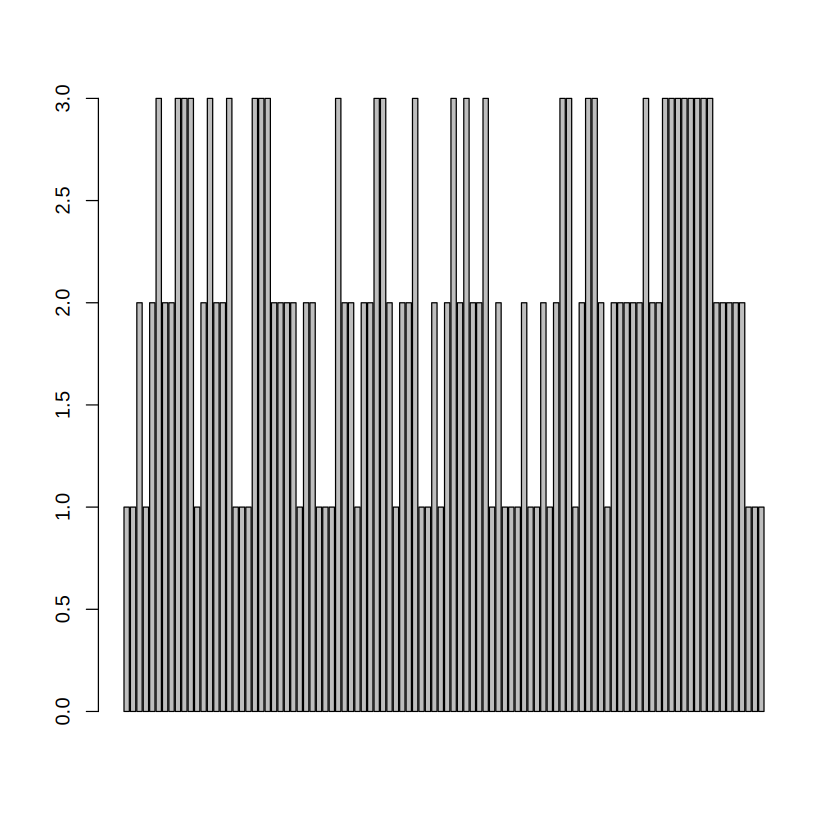

In [ ]:
barplot(direction)                          # again, not what we want

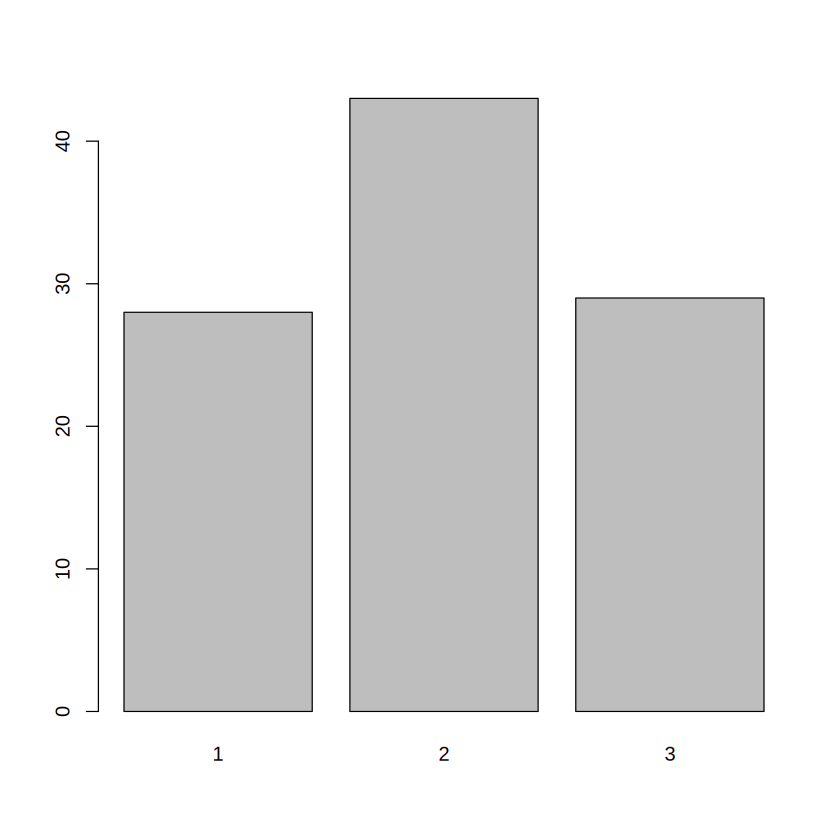

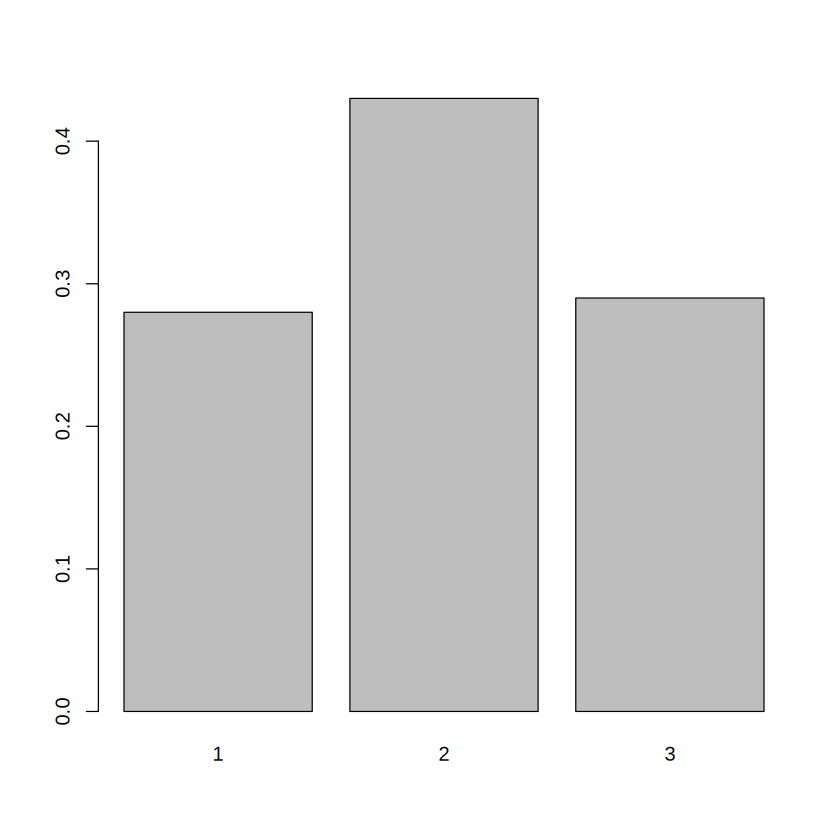

In [ ]:
barplot(table(direction))
barplot(table(direction) / length(direction))

### Customising: colours, title, legend, subtitle, axis labels

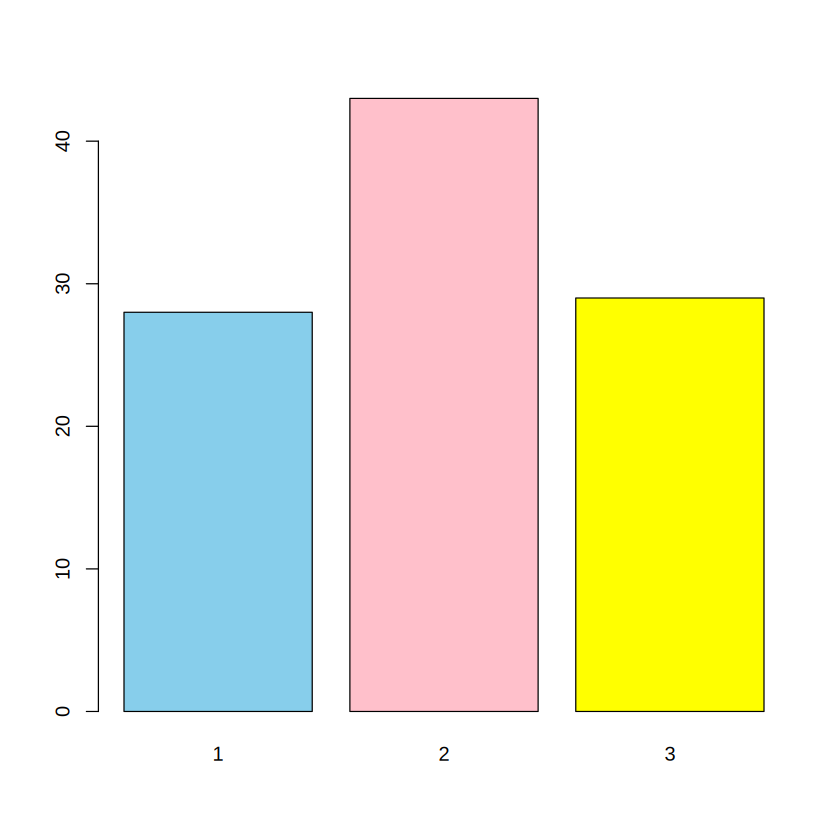

In [ ]:
# Colours
barplot(table(direction), col = c("sky blue", "pink", "yellow"))

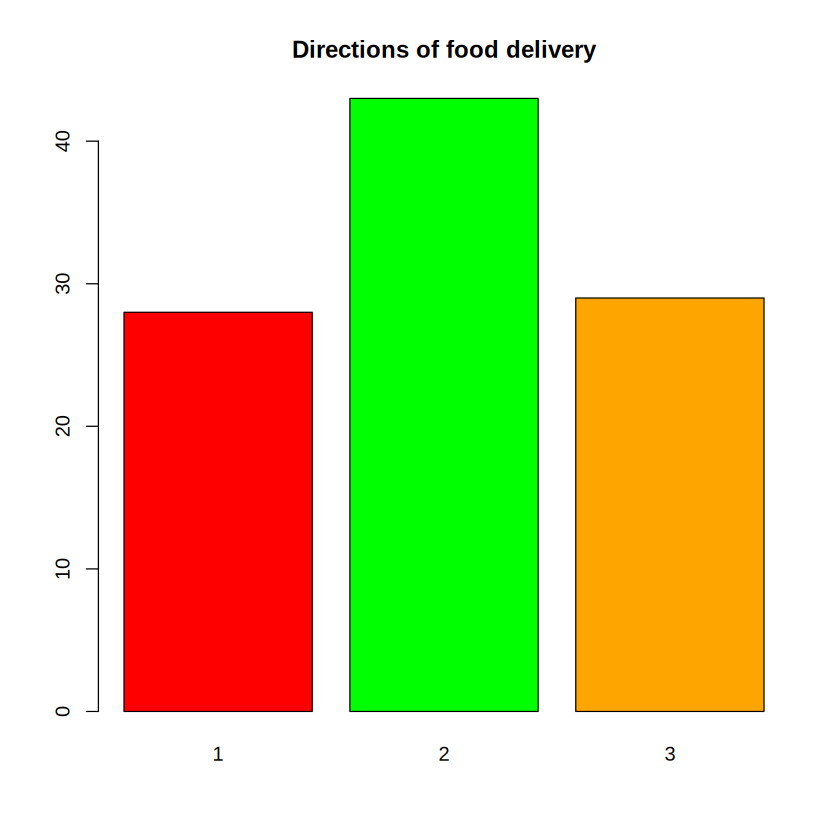

In [ ]:
# Title
barplot(table(direction), col = c("red", "green", "orange"),
        main = "Directions of food delivery")

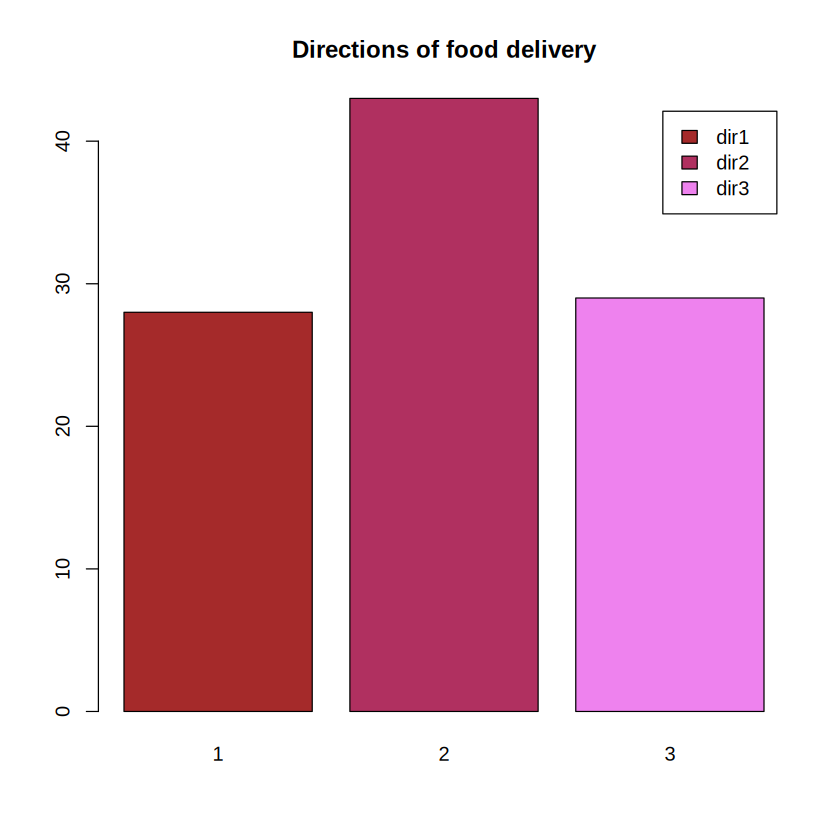

In [ ]:
# Legend
barplot(table(direction), col = c("brown", "maroon", "violet"),
        main = "Directions of food delivery",
        legend.text = c("dir1", "dir2", "dir3"))

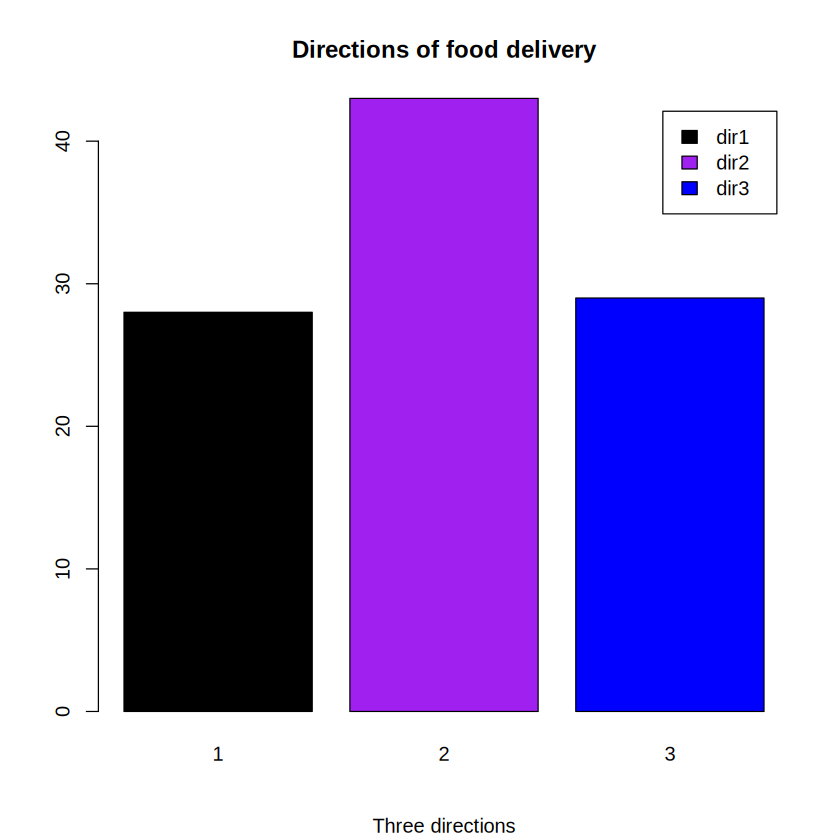

In [ ]:
# Subtitle
barplot(table(direction), col = c("black", "purple", "blue"),
        main = "Directions of food delivery",
        legend.text = c("dir1", "dir2", "dir3"),
        sub = "Three directions")

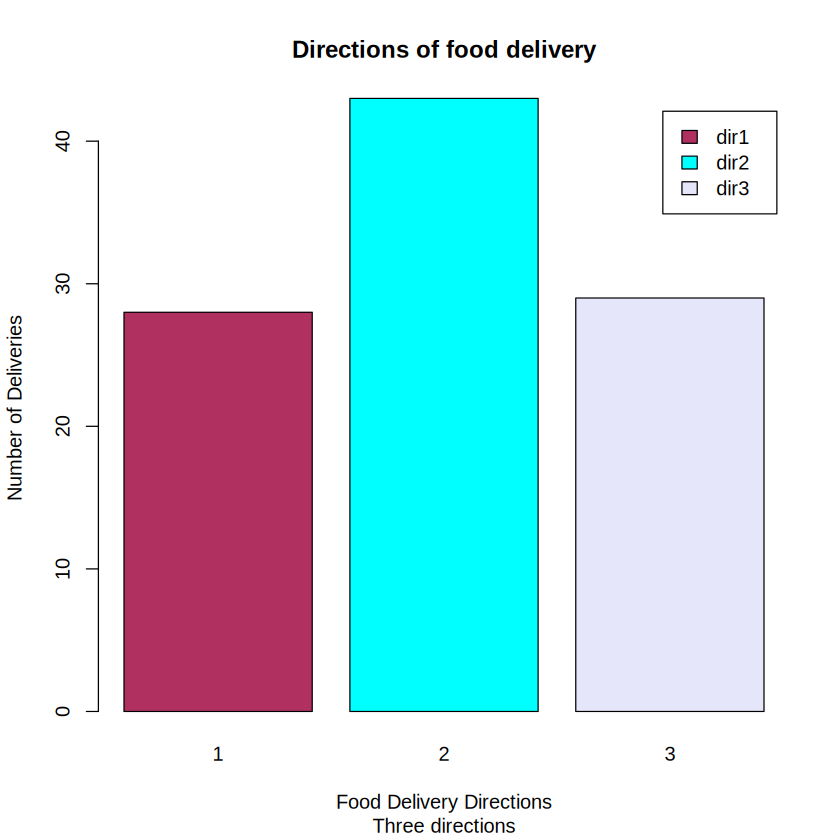

In [ ]:
# Axis labels (full example)green
barplot(table(direction), col = c("maroon", "cyan", "lavender"),
        main = "Directions of food delivery",
        legend.text = c("dir1", "dir2", "dir3"),
        sub = "Three directions",
        xlab = "Food Delivery Directions",
        ylab = "Number of Deliveries")

### Bonus: `barplot()` arguments

In [ ]:
help("barplot")